# ỨNG DỤNG 3 — HÀNH VI KHÁCH HÀNG THƯƠNG MẠI ĐIỆN TỬ

Notebook tái hiện **mục 4** của báo cáo `A02_CT_khoipv.447.pdf`: phân loại nhị phân trên dữ liệu
*Women's Clothing E-Commerce Reviews*, dự đoán nhãn `Recommended IND` từ nội dung review, so
sánh 4 mô hình và lưu `tfidf_vectorizer.sav` + weight cho tầng triển khai (`REST_API.py`).

| Mục báo cáo | Nội dung | Mục notebook |
| --- | --- | --- |
| 4.1 | Bài toán, dữ liệu và target | 1 – 2 |
| 4.2 | Làm sạch, biểu diễn văn bản và EDA | 3 – 5 |
| 4.3 | Phát triển, đánh giá và chọn mô hình | 6 – 9 |
| 4.4 | Triển khai (lưu weight, gọi API) | 10 – 11 |

## 1. Mô tả bài toán và dữ liệu

**Bài toán.** Phân loại nhị phân — dự đoán `Recommended IND`: **1 = khách hàng khuyến nghị sản
phẩm**, **0 = không khuyến nghị**, chỉ dựa trên nội dung review.

**Biểu diễn dữ liệu.** Khác hai ứng dụng trước (vector số có sẵn), ở đây đầu vào là **văn bản
tự do**. Quy trình biểu diễn:

```
Title + Review Text  ->  clean_text (lowercase, bo ky tu khong phai chu)
                     ->  TF-IDF (unigram + bigram)  ->  vector thua 5000 chieu
```

**TF-IDF** cân mỗi từ theo hai thành phần: *term frequency* (từ xuất hiện bao nhiêu lần trong
review này) nhân *inverse document frequency* (từ hiếm trong toàn bộ tập review thì nặng hơn).
Nhờ vậy những từ mang ý kiến thật sự (`disappointed`, `perfect`, `returned`) được đánh trọng số
cao hơn các từ phổ biến vô nghĩa.

**Chỉ số đánh giá.** Dữ liệu lệch lớp mạnh (~82% khuyến nghị) nên Accuracy không đủ — báo cáo
dùng **F1-score, Recall và ROC-AUC**.

In [1]:
import json
import pickle
import re
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
matplotlib.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid")

CSV_NAME = "Womens Clothing E-Commerce Reviews.csv"
CANDIDATES = [
    Path("../data") / CSV_NAME,
    Path("data") / CSV_NAME,
    Path("src/Assignment 02/customer_comments/data") / CSV_NAME,
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Khong tim thay dataset. Da thu: " + "; ".join(map(str, CANDIDATES)))
DATA_PATH = DATA_PATH.resolve()

APP_DIR = DATA_PATH.parent.parent          # .../customer_comments
MODEL_DIR = APP_DIR / "models"
FIGURE_DIR = APP_DIR / "report" / "figures"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / name, bbox_inches="tight")


print("Du lieu :", DATA_PATH)
print("Weight  :", MODEL_DIR)
print("Hinh ve :", FIGURE_DIR)

Du lieu : /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 02/customer_comments/data/Womens Clothing E-Commerce Reviews.csv
Weight  : /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 02/customer_comments/models
Hinh ve : /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 02/customer_comments/report/figures


## 2. Nạp dữ liệu

In [2]:
df_raw = pd.read_csv(DATA_PATH, index_col=0)
print("Kich thuoc:", df_raw.shape)
df_raw.head()

Kich thuoc: (23486, 10)


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Clothing ID              23486 non-null  int64
 1   Age                      23486 non-null  int64
 2   Title                    19676 non-null  str  
 3   Review Text              22641 non-null  str  
 4   Rating                   23486 non-null  int64
 5   Recommended IND          23486 non-null  int64
 6   Positive Feedback Count  23486 non-null  int64
 7   Division Name            23472 non-null  str  
 8   Department Name          23472 non-null  str  
 9   Class Name               23472 non-null  str  
dtypes: int64(5), str(5)
memory usage: 1.8 MB


In [4]:
TARGET = "Recommended IND"

print("Phan bo nhan:")
print(df_raw[TARGET].value_counts().rename({0: "Khong khuyen nghi (0)", 1: "Khuyen nghi (1)"}))
print("\nTy le lop 1: {:.2%}".format(df_raw[TARGET].mean()))
print("\nGia tri thieu:")
print(df_raw[["Title", "Review Text", TARGET]].isna().sum())

Phan bo nhan:
Recommended IND
Khuyen nghi (1)          19314
Khong khuyen nghi (0)     4172
Name: count, dtype: int64

Ty le lop 1: 82.24%

Gia tri thieu:
Title              3810
Review Text         845
Recommended IND       0
dtype: int64


## 3. Làm sạch và biểu diễn văn bản

Theo mục 4.2 của báo cáo: **ghép `Title` với `Review Text`**, chuyển về chữ thường, loại bỏ
nhiễu, rồi TF-IDF hoá.

Hàm `clean_text` dưới đây là **hợp đồng chung giữa notebook và API** — `REST_API.py` phải dùng
đúng hàm này, nếu không văn bản lúc inference sẽ được chuẩn hoá khác lúc huấn luyện và vector
TF-IDF sẽ lệch.

In [5]:
def clean_text(text):
    """Chuan hoa van ban truoc khi TF-IDF (dung chung voi REST_API.py)."""
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)      # bo so, dau cau, ky tu dac biet
    return re.sub(r"\s+", " ", text).strip()   # gop khoang trang thua


df = df_raw.copy()
df["full_text"] = (df["Title"].fillna("") + " " + df["Review Text"].fillna("")).str.strip()

before = len(df)
df = df[df["full_text"].str.len() > 0].copy()
print(f"Bo {before - len(df)} review rong -> con {len(df)} review")

df["clean_text"] = df["full_text"].apply(clean_text)

display(df[["Title", "Review Text", "clean_text", TARGET]].head(3))

print("\nVi du mot review truoc va sau khi lam sach:")
print("Truoc:", df["full_text"].iloc[1][:160])
print("Sau  :", df["clean_text"].iloc[1][:160])

Bo 844 review rong -> con 22642 review


,Title,Review Text,clean_text,Recommended IND
0,NaN,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky and sexy and comfor...,1
1,NaN,Love this dress! it's sooo pretty. i happene...,love this dress it s sooo pretty i happened to...,1
2,Some major design flaws,I had such high hopes for this dress and reall...,some major design flaws i had such high hopes ...,0



Vi du mot review truoc va sau khi lam sach:
Truoc: Love this dress!  it's sooo pretty.  i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite.  i bought a pe
Sau  : love this dress it s sooo pretty i happened to find it in a store and i m glad i did bc i never would have ordered it online bc it s petite i bought a petite an


## 4. Phân tích khám phá dữ liệu (EDA)

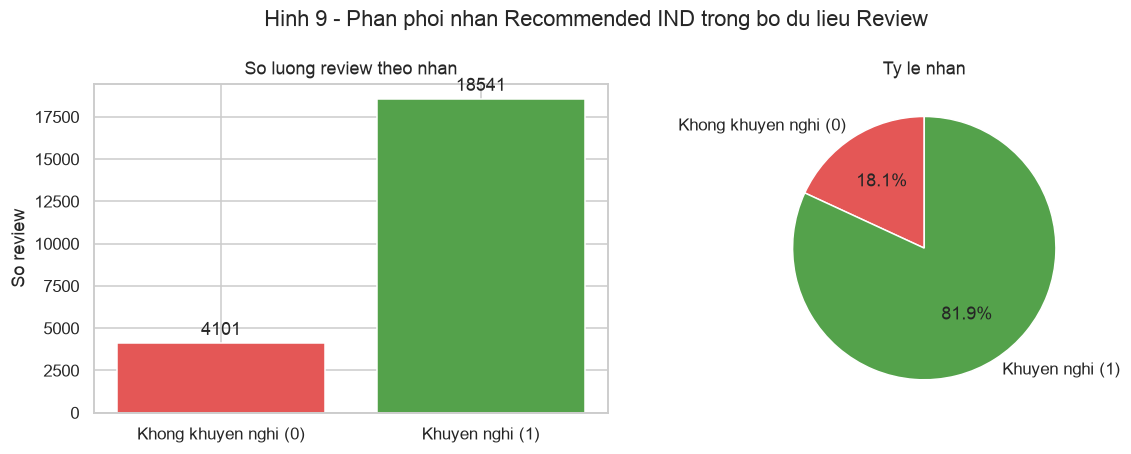

In [6]:
# Hinh 9 cua bao cao: phan phoi nhan Recommended IND
counts = df[TARGET].value_counts().sort_index()
labels = ["Khong khuyen nghi (0)", "Khuyen nghi (1)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bars = axes[0].bar(labels, counts.values, color=["#E45756", "#54A24B"])
axes[0].bar_label(bars, fmt="%d", padding=3)
axes[0].set_title("So luong review theo nhan")
axes[0].set_ylabel("So review")

axes[1].pie(counts.values, labels=labels, autopct="%1.1f%%",
            colors=["#E45756", "#54A24B"], startangle=90)
axes[1].set_title("Ty le nhan")

plt.suptitle("Hinh 9 - Phan phoi nhan Recommended IND trong bo du lieu Review")
save_figure("customer_label_distribution.png")
plt.show()

=> Dữ liệu lệch lớp mạnh: hơn 82% review là khuyến nghị. Một mô hình luôn đoán "khuyến nghị"
đã đạt Accuracy 82% — đây là lý do phải dùng `class_weight="balanced"` và đánh giá bằng
F1/Recall/ROC-AUC.

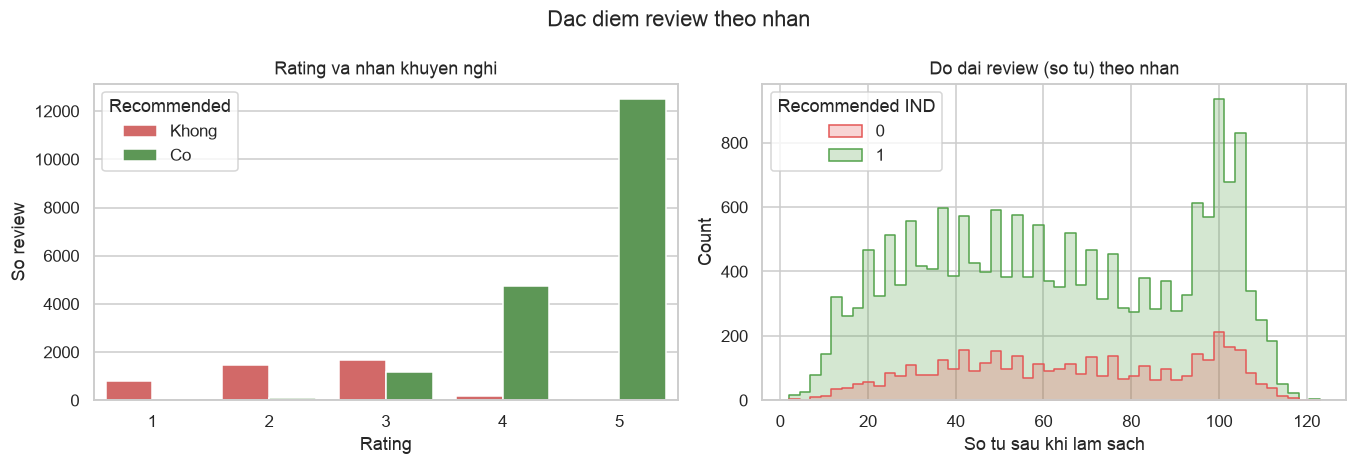

Do dai review trung binh: 63.7 tu


In [7]:
# Quan he giua Rating va nhan khuyen nghi
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

sns.countplot(data=df, x="Rating", hue=TARGET, ax=axes[0],
              palette={0: "#E45756", 1: "#54A24B"})
axes[0].set_title("Rating va nhan khuyen nghi")
axes[0].set_ylabel("So review")
axes[0].legend(title="Recommended", labels=["Khong", "Co"])

df["text_length"] = df["clean_text"].str.split().str.len()
sns.histplot(data=df, x="text_length", hue=TARGET, bins=50, ax=axes[1],
             palette={0: "#E45756", 1: "#54A24B"}, element="step")
axes[1].set_title("Do dai review (so tu) theo nhan")
axes[1].set_xlabel("So tu sau khi lam sach")

plt.suptitle("Dac diem review theo nhan")
save_figure("customer_rating_and_length.png")
plt.show()

print("Do dai review trung binh: {:.1f} tu".format(df["text_length"].mean()))

=> `Rating` tách nhãn gần như hoàn hảo (rating 1–2 hầu hết là không khuyến nghị), nhưng **không
được dùng làm đặc trưng**: lúc inference người dùng chỉ nhập văn bản review, không nhập rating.
Mô hình phải học từ chính nội dung chữ.

## 5. Chia tập và vector hoá TF-IDF

Thứ tự quan trọng: **chia tập trước, `fit` vectorizer sau** và chỉ `fit` trên tập train. Nếu
`fit` trên toàn bộ dữ liệu, từ vựng và trọng số IDF sẽ mang thông tin của tập test — đúng loại
rò rỉ dữ liệu mà mục 5.1 của báo cáo cảnh báo.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TEST_SIZE = 0.2
MAX_FEATURES = 5000

X_text = df["clean_text"]
y = df[TARGET]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f"Train: {len(X_train_text)} review | Test: {len(X_test_text)} review")

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),       # unigram + bigram, theo muc 4.2 bao cao
    min_df=2,                 # bo tu chi xuat hien trong 1 review
    max_features=MAX_FEATURES,
    stop_words="english",     # bo tu chuc nang khong mang y kien
)

X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print(f"\nKich thuoc ma tran TF-IDF: train {X_train.shape}, test {X_test.shape}")
print("Do thua cua ma tran train: {:.3%} o khac 0".format(X_train.nnz / (X_train.shape[0] * X_train.shape[1])))

Train: 18113 review | Test: 4529 review



Kich thuoc ma tran TF-IDF: train (18113, 5000), test (4529, 5000)
Do thua cua ma tran train: 0.588% o khac 0


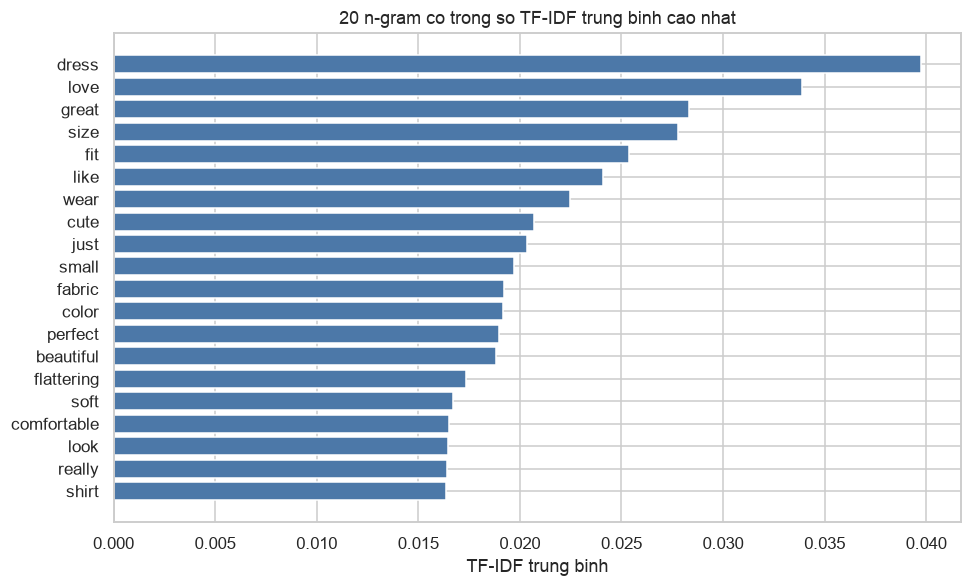

So unigram: 2169 | So bigram: 2831


In [9]:
# Nhung n-gram co trong so TF-IDF trung binh cao nhat
mean_tfidf = pd.Series(np.asarray(X_train.mean(axis=0)).ravel(), index=vectorizer.get_feature_names_out())
top_terms = mean_tfidf.sort_values(ascending=False).head(20).sort_values()

plt.figure(figsize=(9, 5.5))
plt.barh(top_terms.index, top_terms.values, color="#4C78A8")
plt.title("20 n-gram co trong so TF-IDF trung binh cao nhat")
plt.xlabel("TF-IDF trung binh")
save_figure("customer_top_tfidf_terms.png")
plt.show()

n_bigrams = sum(1 for t in vectorizer.get_feature_names_out() if " " in t)
print(f"So unigram: {MAX_FEATURES - n_bigrams} | So bigram: {n_bigrams}")

## 6. Mô hình cơ sở (baseline)

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

pd.DataFrame([{
    "Model": "Baseline (luon doan 'khuyen nghi')",
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1-score": f1_score(y_test, baseline_pred, zero_division=0),
}]).round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Baseline (luon doan 'khuyen nghi'),0.8189,0.8189,1.0,0.9005


=> Baseline đạt Accuracy ~82% và Recall 100% nhưng vô dụng: nó không bao giờ phát hiện được
review tiêu cực — đúng nhóm mà doanh nghiệp cần biết nhất.

## 7. Huấn luyện 4 mô hình phân loại

Bốn mô hình theo mục 4.3 của báo cáo. Ba mô hình tuyến tính dùng `class_weight="balanced"` để
bù lệch lớp; Multinomial Naive Bayes không có tham số này nhưng vốn rất hợp với đặc trưng đếm
từ / TF-IDF.

In [11]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

MODEL_SPECS = {
    "logistic_regression": (
        "Logistic Regression (Balanced)",
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    ),
    "linear_svm": (
        "Linear SVM",
        LinearSVC(class_weight="balanced", random_state=42),
    ),
    "naive_bayes": (
        "Multinomial Naive Bayes",
        MultinomialNB(),
    ),
    "sgd": (
        "SGD Classifier",
        SGDClassifier(loss="modified_huber", class_weight="balanced",
                      max_iter=1000, random_state=42),
    ),
}

trained_models, results = {}, []
for key, (display_name, estimator) in MODEL_SPECS.items():
    estimator.fit(X_train, y_train)
    trained_models[key] = estimator

    y_pred = estimator.predict(X_test)
    if hasattr(estimator, "predict_proba"):
        y_score = estimator.predict_proba(X_test)[:, 1]
    else:
        y_score = estimator.decision_function(X_test)

    results.append({
        "Key": key, "Model": display_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score),
    })
    print(f"{display_name:32s} F1 = {results[-1]['F1-score']:.4f} | ROC-AUC = {results[-1]['ROC-AUC']:.4f}")

results_df = pd.DataFrame(results).set_index("Key")
results_df.round(4)

Logistic Regression (Balanced)   F1 = 0.9230 | ROC-AUC = 0.9406
Linear SVM                       F1 = 0.9217 | ROC-AUC = 0.9266
Multinomial Naive Bayes          F1 = 0.9291 | ROC-AUC = 0.9359
SGD Classifier                   F1 = 0.9219 | ROC-AUC = 0.9303


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
Key,,,,,,
logistic_regression,Logistic Regression (Balanced),0.8790,0.9634,0.8860,0.9230,0.9406
linear_svm,Linear SVM,0.8752,0.9481,0.8967,0.9217,0.9266
naive_bayes,Multinomial Naive Bayes,0.8777,0.8847,0.9782,0.9291,0.9359
sgd,SGD Classifier,0.8764,0.9544,0.8916,0.9219,0.9303


## 8. Đánh giá và chọn mô hình

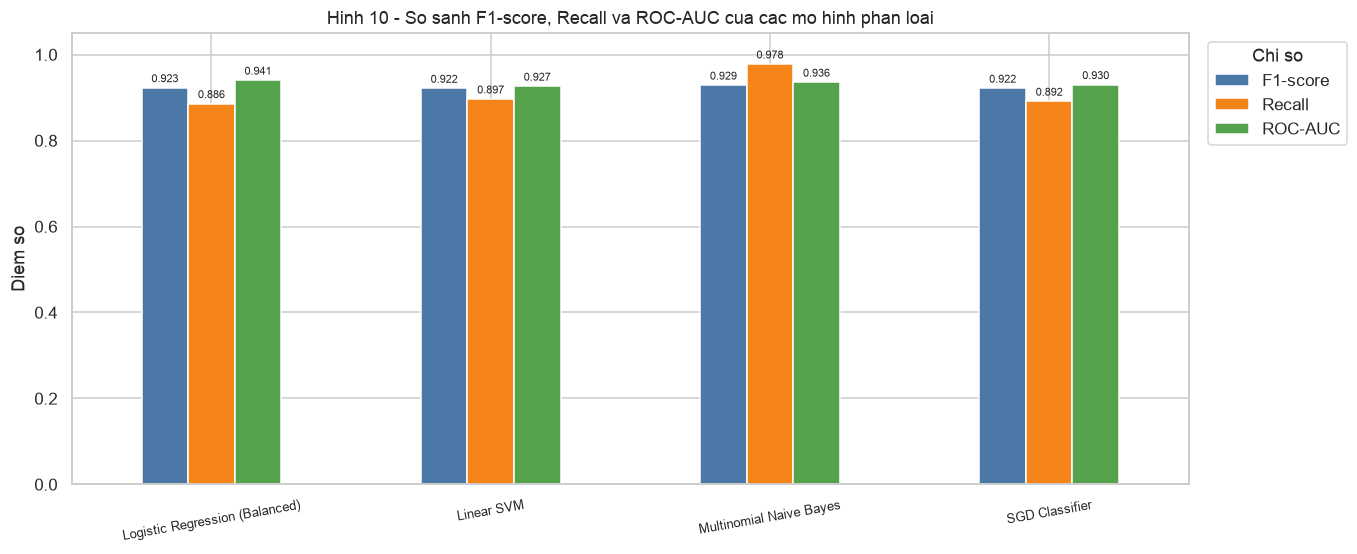

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Multinomial Naive Bayes,0.8777,0.8847,0.9782,0.9291,0.9359
Logistic Regression (Balanced),0.8790,0.9634,0.8860,0.9230,0.9406
SGD Classifier,0.8764,0.9544,0.8916,0.9219,0.9303
Linear SVM,0.8752,0.9481,0.8967,0.9217,0.9266


In [12]:
# Hinh 10 cua bao cao: so sanh F1, Recall va ROC-AUC
plot_df = results_df.set_index("Model")[["F1-score", "Recall", "ROC-AUC"]]

ax = plot_df.plot(kind="bar", figsize=(12.5, 5.2),
                  color=["#4C78A8", "#F58518", "#54A24B"])
ax.set_title("Hinh 10 - So sanh F1-score, Recall va ROC-AUC cua cac mo hinh phan loai")
ax.set_ylabel("Diem so")
ax.set_xlabel("")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=10, fontsize=8.5)
plt.legend(title="Chi so", bbox_to_anchor=(1.01, 1), loc="upper left")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=7.5)
save_figure("customer_model_comparison.png")
plt.show()

display(results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]]
        .round(4).sort_values("F1-score", ascending=False))

In [13]:
BEST_F1_KEY = results_df["F1-score"].idxmax()
BEST_AUC_KEY = results_df["ROC-AUC"].idxmax()
DEFAULT_MODEL = "logistic_regression"     # muc 4.3 bao cao: uu tien kha nang giai thich

print("F1 cao nhat     : {} ({:.2%})".format(
    results_df.loc[BEST_F1_KEY, "Model"], results_df.loc[BEST_F1_KEY, "F1-score"]))
print("ROC-AUC cao nhat: {} ({:.4f})".format(
    results_df.loc[BEST_AUC_KEY, "Model"], results_df.loc[BEST_AUC_KEY, "ROC-AUC"]))

row = results_df.loc[DEFAULT_MODEL]
print("\nMo hinh chon de deploy: {}".format(row["Model"]))
for metric in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]:
    print(f"  {metric:10s}: {row[metric]:.4f}")

F1 cao nhat     : Multinomial Naive Bayes (92.91%)
ROC-AUC cao nhat: Logistic Regression (Balanced) (0.9406)

Mo hinh chon de deploy: Logistic Regression (Balanced)
  Accuracy  : 0.8790
  Precision : 0.9634
  Recall    : 0.8860
  F1-score  : 0.9230
  ROC-AUC   : 0.9406


=> Khớp với kết quả nêu ở mục 4.3 của báo cáo: **Multinomial Naive Bayes đạt F1 cao nhất
(≈ 93%)**, nhưng **Logistic Regression Balanced** (Accuracy ≈ 87.9%, Precision ≈ 96.3%,
Recall ≈ 88.6%, F1 ≈ 92.3%, ROC-AUC ≈ 0.940) được chọn làm mặc định vì hai lý do:

1. **ROC-AUC cao nhất** — xác suất nó trả về đáng tin hơn, quan trọng khi giao diện hiển thị
   "độ tin cậy %".
2. **Khả năng diễn giải** — hệ số của mỗi từ cho biết chính xác từ nào đẩy dự đoán về phía
   khuyến nghị hay không khuyến nghị (xem mục 9).

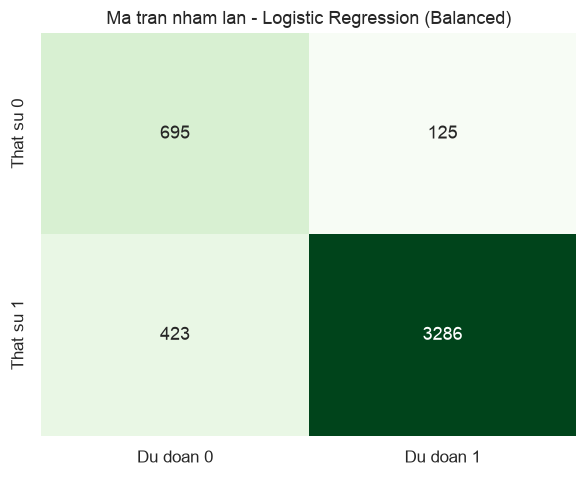

TN = 695 | FP = 125 | FN = 423 | TP = 3286

                   precision    recall  f1-score   support

Khong khuyen nghi       0.62      0.85      0.72       820
      Khuyen nghi       0.96      0.89      0.92      3709

         accuracy                           0.88      4529
        macro avg       0.79      0.87      0.82      4529
     weighted avg       0.90      0.88      0.89      4529



In [14]:
# Ma tran nham lan cua mo hinh deploy
best_model = trained_models[DEFAULT_MODEL]
y_pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=["Du doan 0", "Du doan 1"],
            yticklabels=["That su 0", "That su 1"])
plt.title(f"Ma tran nham lan - {results_df.loc[DEFAULT_MODEL, 'Model']}")
save_figure("customer_confusion_matrix.png")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}")
print()
print(classification_report(y_test, y_pred, target_names=["Khong khuyen nghi", "Khuyen nghi"]))

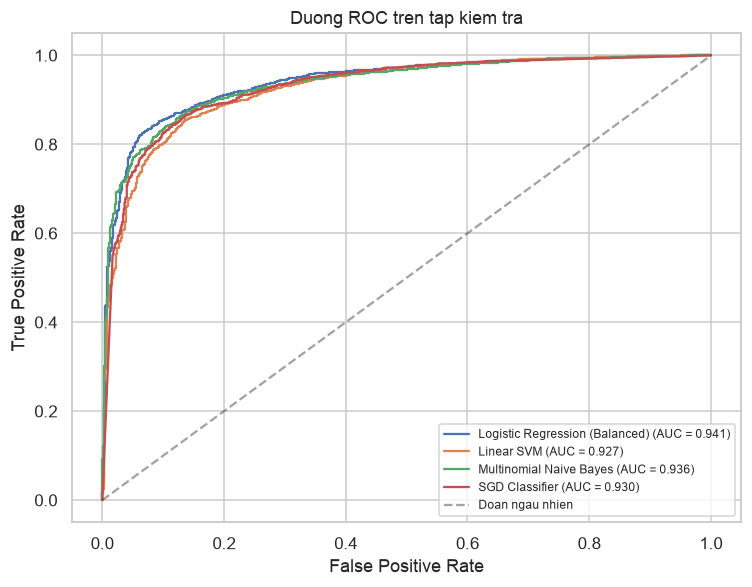

In [15]:
# Duong ROC cua 4 mo hinh
plt.figure(figsize=(7, 5.5))
for key, model in trained_models.items():
    if hasattr(model, "predict_proba"):
        score = model.predict_proba(X_test)[:, 1]
    else:
        score = model.decision_function(X_test)
    fpr, tpr, _ = roc_curve(y_test, score)
    plt.plot(fpr, tpr, label=f"{results_df.loc[key, 'Model']} (AUC = {roc_auc_score(y_test, score):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Doan ngau nhien")
plt.title("Duong ROC tren tap kiem tra")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=8)
save_figure("customer_roc_curves.png")
plt.show()

## 9. Diễn giải trọng số từ

Lợi thế chính của Logistic Regression trên không gian văn bản: mỗi n-gram có một hệ số, đọc
trực tiếp được mô hình đang dựa vào từ nào.

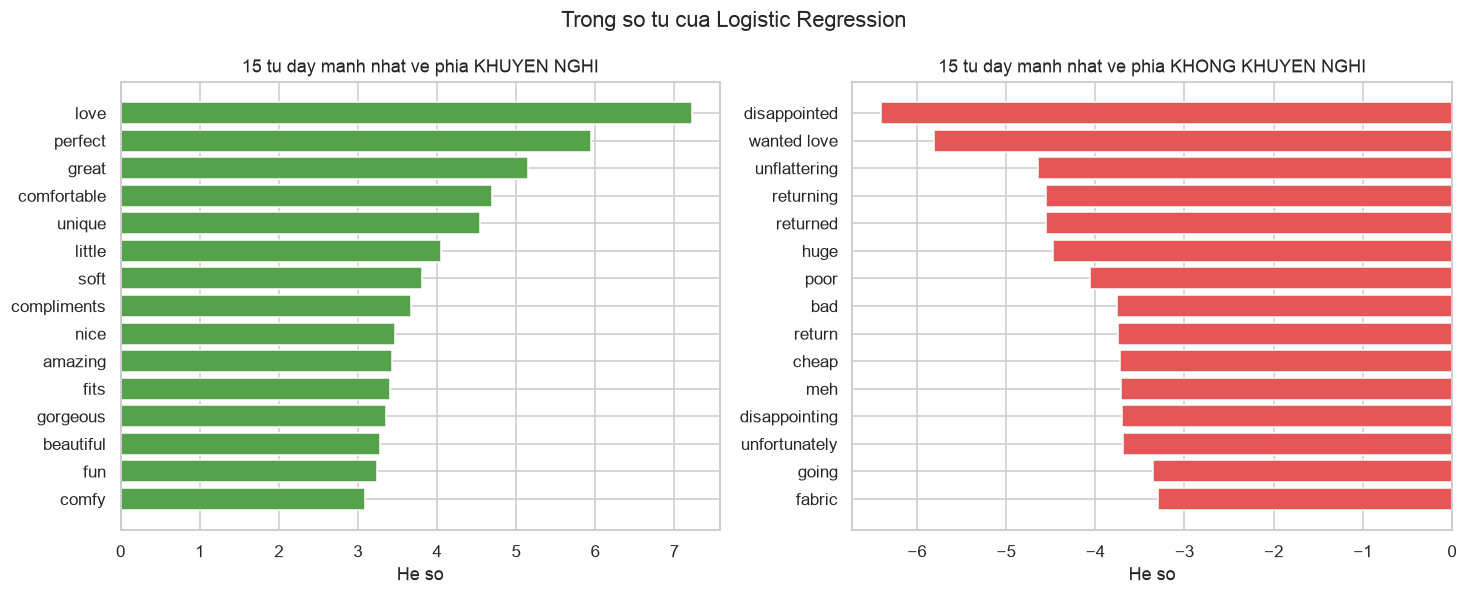

In [16]:
coefficients = pd.Series(
    trained_models[DEFAULT_MODEL].coef_[0], index=vectorizer.get_feature_names_out()
)
top_positive = coefficients.sort_values(ascending=False).head(15)
top_negative = coefficients.sort_values().head(15)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
axes[0].barh(top_positive.index[::-1], top_positive.values[::-1], color="#54A24B")
axes[0].set_title("15 tu day manh nhat ve phia KHUYEN NGHI")
axes[0].set_xlabel("He so")

axes[1].barh(top_negative.index[::-1], top_negative.values[::-1], color="#E45756")
axes[1].set_title("15 tu day manh nhat ve phia KHONG KHUYEN NGHI")
axes[1].set_xlabel("He so")

plt.suptitle("Trong so tu cua Logistic Regression")
save_figure("customer_feature_weights.png")
plt.show()

=> Các từ tiêu cực mạnh nhất (`returned`, `disappointed`, `unfortunately`, `cheap`) và tích cực
mạnh nhất (`perfect`, `love`, `compliments`) đúng với trực giác ngôn ngữ — bằng chứng mô hình
học được tín hiệu ý kiến thật chứ không bắt nhiễu.

## 10. Lưu weight cho tầng triển khai

Phải lưu **hai** thứ và nạp lại **cùng nhau**:

* `tfidf_vectorizer.sav` — từ vựng và trọng số IDF đã học. Thiếu nó thì không có cách nào ánh xạ
  một review mới về đúng 5000 chiều mà model mong đợi.
* `*.sav` — bốn mô hình phân loại.

Cả hai đều được fit lại trên **toàn bộ** dữ liệu trước khi lưu.

In [17]:
from sklearn.base import clone

vectorizer_final = TfidfVectorizer(
    ngram_range=(1, 2), min_df=2, max_features=MAX_FEATURES, stop_words="english",
)
X_all = vectorizer_final.fit_transform(X_text)
print("Ma tran TF-IDF tren toan bo du lieu:", X_all.shape)

with open(MODEL_DIR / "tfidf_vectorizer.sav", "wb") as f:
    pickle.dump(vectorizer_final, f)
print("Da luu: tfidf_vectorizer.sav")

final_models = {}
for key, (display_name, estimator) in MODEL_SPECS.items():
    model = clone(estimator)
    model.fit(X_all, y)
    final_models[key] = model
    with open(MODEL_DIR / f"{key}.sav", "wb") as f:
        pickle.dump(model, f)
    print("Da luu:", f"{key}.sav")

Ma tran TF-IDF tren toan bo du lieu: (22642, 5000)
Da luu: tfidf_vectorizer.sav
Da luu: logistic_regression.sav
Da luu: linear_svm.sav
Da luu: naive_bayes.sav
Da luu: sgd.sav


In [18]:
metadata = {
    "task": "binary_classification",
    "dataset": "Womens Clothing E-Commerce Reviews",
    "n_samples": int(len(df)),
    "target": TARGET,
    "text_fields": ["Title", "Review Text"],
    "vectorizer": "tfidf_vectorizer.sav",
    "vectorizer_params": {
        "ngram_range": [1, 2], "min_df": 2,
        "max_features": MAX_FEATURES, "stop_words": "english",
    },
    "random_state": RANDOM_STATE,
    "default_model": DEFAULT_MODEL,
    "best_f1_model": BEST_F1_KEY,
    "labels": {"0": "Không khuyến nghị", "1": "Khuyến nghị"},
    "models": {
        key: {
            "file": f"{key}.sav",
            "display_name": results_df.loc[key, "Model"],
            "has_proba": hasattr(final_models[key], "predict_proba"),
            "test_metrics": {
                "Accuracy": round(float(results_df.loc[key, "Accuracy"]), 4),
                "Precision": round(float(results_df.loc[key, "Precision"]), 4),
                "Recall": round(float(results_df.loc[key, "Recall"]), 4),
                "F1-score": round(float(results_df.loc[key, "F1-score"]), 4),
                "ROC-AUC": round(float(results_df.loc[key, "ROC-AUC"]), 4),
            },
        }
        for key in MODEL_SPECS
    },
}

with open(MODEL_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Da luu: metadata.json")
print(json.dumps(metadata["models"][DEFAULT_MODEL], ensure_ascii=False, indent=2))

Da luu: metadata.json
{
  "file": "logistic_regression.sav",
  "display_name": "Logistic Regression (Balanced)",
  "has_proba": true,
  "test_metrics": {
    "Accuracy": 0.879,
    "Precision": 0.9634,
    "Recall": 0.886,
    "F1-score": 0.923,
    "ROC-AUC": 0.9406
  }
}


### 10.1. Kiểm tra lại weight vừa lưu

In [19]:
with open(MODEL_DIR / "tfidf_vectorizer.sav", "rb") as f:
    loaded_vectorizer = pickle.load(f)
with open(MODEL_DIR / f"{DEFAULT_MODEL}.sav", "rb") as f:
    loaded_model = pickle.load(f)

samples = [
    "Beautiful dress! The fabric is soft and the fit is perfect. I get compliments every time.",
    "Very disappointed. The material feels cheap and it ran small. I returned it immediately.",
    "Cute top but the sleeves are a bit tight. Still wearable though.",
]

for text in samples:
    vector = loaded_vectorizer.transform([clean_text(text)])
    label = int(loaded_model.predict(vector)[0])
    proba = float(loaded_model.predict_proba(vector)[0][1])
    verdict = "KHUYEN NGHI (1)" if label else "KHONG KHUYEN NGHI (0)"
    print(f"{verdict:24s} P(khuyen nghi) = {proba:6.2%}  |  {text[:62]}...")

KHUYEN NGHI (1)          P(khuyen nghi) = 96.24%  |  Beautiful dress! The fabric is soft and the fit is perfect. I ...
KHONG KHUYEN NGHI (0)    P(khuyen nghi) =  0.34%  |  Very disappointed. The material feels cheap and it ran small. ...
KHUYEN NGHI (1)          P(khuyen nghi) = 54.13%  |  Cute top but the sleeves are a bit tight. Still wearable thoug...


## 11. Triển khai — gọi thử REST API

Tầng ứng dụng nằm ở `customer_comments/REST_API.py` (Flask, cổng **8082**). API nhận chuỗi
`Review Text`, chạy `clean_text`, transform bằng `tfidf_vectorizer.sav` và trả về nhãn cùng xác
suất khuyến nghị — đúng mô tả mục 4.4 của báo cáo.

Mở một Terminal khác rồi chạy:

```bash
cd "src/Assignment 02/customer_comments"
python REST_API.py
```

In [20]:
import requests

payload = {
    "model": "logistic_regression",
    "Title": "Love this dress",
    "Review Text": "The fabric is soft and the fit is perfect. I get compliments every time I wear it.",
}

try:
    response = requests.post("http://127.0.0.1:8082/recommendation/v1/predict", json=payload, timeout=5)
    print("Status:", response.status_code)
    print(json.dumps(response.json(), ensure_ascii=False, indent=2))
except Exception as exc:
    print("Chua goi duoc API (co the server chua chay):", exc)
    print("Hay chay: cd 'src/Assignment 02/customer_comments' && python REST_API.py")

Status: 200
{
  "cleaned_text": "love this dress the fabric is soft and the fit is perfect i get compliments every time i wear it",
  "label": "Khuyen nghi",
  "matched_terms": 16,
  "metrics": {
    "Accuracy": 0.879,
    "F1-score": 0.923,
    "Precision": 0.9634,
    "ROC-AUC": 0.9406,
    "Recall": 0.886
  },
  "model": "logistic_regression",
  "model_name": "Logistic Regression (Balanced)",
  "prediction": 1,
  "probability": 97.08,
  "success": true,
  "top_terms": [
    {
      "direction": "positive",
      "term": "perfect",
      "weight": 0.8935
    },
    {
      "direction": "positive",
      "term": "compliments",
      "weight": 0.8673
    },
    {
      "direction": "positive",
      "term": "love",
      "weight": 0.7767
    },
    {
      "direction": "positive",
      "term": "soft",
      "weight": 0.6186
    },
    {
      "direction": "negative",
      "term": "fabric",
      "weight": -0.5328
    },
    {
      "direction": "positive",
      "term": "love dress",

## 12. Kết luận

| Nội dung | Kết quả |
| --- | --- |
| Biểu diễn | `Title + Review Text` → `clean_text` → TF-IDF unigram/bigram, 5000 chiều |
| Mô hình F1 cao nhất | **Multinomial Naive Bayes** (F1 ≈ 93%) |
| Mô hình deploy | **Logistic Regression Balanced** — Acc ≈ 87.9%, P ≈ 96.3%, R ≈ 88.6%, F1 ≈ 92.3%, AUC ≈ 0.940 |
| Weight | `tfidf_vectorizer.sav` + `models/*.sav` + `metadata.json` |
| Triển khai | Flask REST API `POST /recommendation/v1/predict` (cổng 8082) + giao diện Web |

Các mô hình **tuyến tính** (Logistic Regression, Linear SVM) và **Naive Bayes** hoạt động đặc
biệt tốt trên không gian văn bản nhiều chiều: với 5000 đặc trưng thưa, dữ liệu gần như luôn
phân tách tuyến tính được, nên mô hình phức tạp hơn chỉ thêm phương sai chứ không thêm độ chính
xác. Giới hạn: TF-IDF là *bag-of-words* nên không nắm được phủ định xa ("not a single thing I
liked") hay mỉa mai — muốn xử lý được phải chuyển sang mô hình ngôn ngữ theo ngữ cảnh.